# RC3SI — Stage 05: Held-Out Test Evaluation & Export

**Goal:** evaluate the *frozen, Stage 04-selected* binary irrigation-pattern classifier **once** on Stage 03's held-out chronological test partition, document its limitations, and prepare a reproducible inference package for FastAPI.

**Requires both original archives:** `RC3SI_Stage03_Outputs_v1.zip` (test features) and `RC3SI_Stage04_Outputs_v1.zip` (frozen trained model and selection manifest).

**Class meaning:** 0 = measurements from 100%-irrigation Line 1; 1 = measurements from 30%-irrigation Line 3. Not a diagnosis of physiological plant stress or an early-warning system. One line per treatment, one field, one growing season; estimates are **within-season, same-line test performance** only.

**Scientific rule:** do not retrain, reselect features, recalibrate, change threshold or perform a new search using the held-out test set. Stage 05 only audits and evaluates the frozen Stage 04 artifact.

## Cell 1 — Install and import dependencies

In [1]:
!pip -q install "scikit-learn==1.6.1" pandas numpy matplotlib seaborn joblib

## Cell 2 — Imports and reproducibility

In [2]:
import io, json, zipfile, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    matthews_corrcoef, log_loss, brier_score_loss)
np.random.seed(42)
print('Python:', platform.python_version(), '| sklearn:', sklearn.__version__)

Python: 3.13.16 | sklearn: 1.6.1


## Cell 3 — Upload **both** prior-stage ZIP files (Colab)

In [3]:
Z3 = Path('RC3SI_Stage03_Outputs_v1.zip')
Z4 = Path('RC3SI_Stage04_Outputs_v1.zip')
if not Z3.exists() or not Z4.exists():
    try:
        from google.colab import files
        print('Upload both Stage 03 and Stage 04 ZIP archives.')
        files.upload()
    except ImportError:
        print('Not in Colab: put both ZIPs in this notebook working directory.')
assert Z3.is_file(), f'Missing: {Z3}'
assert Z4.is_file(), f'Missing: {Z4}'
print('Archives found:', Z3, Z4)

Upload both Stage 03 and Stage 04 ZIP archives.


Saving RC3SI_Stage04_Outputs_v1.zip to RC3SI_Stage04_Outputs_v1.zip
Saving RC3SI_Stage03_Outputs_v1.zip to RC3SI_Stage03_Outputs_v1.zip
Archives found: RC3SI_Stage03_Outputs_v1.zip RC3SI_Stage04_Outputs_v1.zip


## Cell 4 — Read original exports without silently replacing files

In [4]:
with zipfile.ZipFile(Z3) as z3:
    assert {'parma2023_binary_engineered.csv','stage03_manifest.json'} <= set(z3.namelist())
    stage03_manifest=json.loads(z3.read('stage03_manifest.json'))
    data=pd.read_csv(io.BytesIO(z3.read('parma2023_binary_engineered.csv')),parse_dates=['timestamp'])
with zipfile.ZipFile(Z4) as z4:
    assert {'stage04_manifest.json','selected_validation_model_train_only.joblib'} <= set(z4.namelist())
    stage04_manifest=json.loads(z4.read('stage04_manifest.json'))
    model_bytes=z4.read('selected_validation_model_train_only.joblib')
print('Rows by split:')
print(data.groupby('split').size())
print('Selected model:',stage04_manifest['selected_model_family'])
print('Selection validation F1:',stage04_manifest['selected_validation_metrics']['f1'])

Rows by split:
split
test           706
train         2165
validation     660
dtype: int64
Selected model: HistGradientBoosting
Selection validation F1: 0.8708609271523179


## Cell 5 — Freeze and verify evaluation protocol

In [5]:
features=list(stage04_manifest['feature_names_ordered'])
assert features==list(stage03_manifest['features_selected_training_only'])
assert stage04_manifest['selected_model_family']=='HistGradientBoosting'
assert stage04_manifest['model_selected_on']=='validation'
assert stage04_manifest['test_evaluated'] is False
assert stage04_manifest['trained_on']==['train']
assert stage04_manifest['prediction_threshold']==0.5
assert len(features)==10 and len(set(features))==10
assert not set(features).intersection({'target','split','line','treatment_percent','timestamp','environment_observed_at'})
assert data['split'].value_counts().to_dict()=={'train':2165,'test':706,'validation':660}
assert not data.loc[data['split'].eq('test'),features+['target']].isna().any().any()
assert set(data['target'].unique())=={0,1}
print('Frozen protocol verified. Threshold: 0.5. Features:', features)

Frozen protocol verified. Threshold: 0.5. Features: ['soil_humidity_lag_1h', 'soil_humidity_lag_6h', 'soil_humidity', 'soil_humidity_lag_3h', 'soil_humidity_prev_3h_mean', 'soil_humidity_prev_6h_mean', 'soil_electrical_conductivity', 'soil_humidity_change_3h', 'soil_humidity_change_1h', 'soil_temperature']


## Cell 6 — Load only the trusted exported model

In [6]:
# joblib uses pickle: ONLY load archives created by your own trusted Stage 04 notebook.
model=joblib.load(io.BytesIO(model_bytes))
assert hasattr(model,'predict_proba')
if hasattr(model,'n_features_in_'):
    assert model.n_features_in_==len(features)
print('Loaded frozen Stage 04 model:',type(model).__name__)
print('Pipeline steps:', list(model.named_steps) if hasattr(model,'named_steps') else 'none')

Loaded frozen Stage 04 model: Pipeline
Pipeline steps: ['imputer', 'classifier']


## Cell 7 — Isolate test rows, with no fitting or tuning

In [7]:
test=data.loc[data['split'].eq('test')].copy().sort_values(['timestamp','line']).reset_index(drop=True)
X_test=test.loc[:,features].copy()
y_test=test['target'].astype(int).to_numpy()
assert len(test)==706 and len(np.unique(y_test))==2
print('Test observations:',len(test),'class counts:',pd.Series(y_test).value_counts().sort_index().to_dict())
print('Date range:',test['timestamp'].min(),'to',test['timestamp'].max())

Test observations: 706 class counts: {0: 353, 1: 353}
Date range: 2023-08-30 06:00:00+00:00 to 2023-09-13 22:00:00+00:00


## Cell 8 — Predict just once at the frozen threshold

In [8]:
THRESHOLD=float(stage04_manifest['prediction_threshold'])
scores=model.predict_proba(X_test)[:,1]
pred=(scores>=THRESHOLD).astype(int)
assert np.isfinite(scores).all() and np.all((0<=scores)&(scores<=1))
print('Predictions generated; prediction rate of class 1:', round(pred.mean(),4))

Predictions generated; prediction rate of class 1: 0.3215


## Cell 9 — Final held-out classification metrics

In [9]:
metrics={
    'accuracy':accuracy_score(y_test,pred),
    'balanced_accuracy':balanced_accuracy_score(y_test,pred),
    'precision':precision_score(y_test,pred,zero_division=0),
    'recall':recall_score(y_test,pred,zero_division=0),
    'f1':f1_score(y_test,pred,zero_division=0),
    'roc_auc':roc_auc_score(y_test,scores),
    'average_precision':average_precision_score(y_test,scores),
    'mcc':matthews_corrcoef(y_test,pred),
    'log_loss':log_loss(y_test,scores,labels=[0,1]),
    'brier_score':brier_score_loss(y_test,scores),
}
print(pd.Series(metrics).round(4).to_string())
print('\nLabel-specific classification report:')
print(classification_report(y_test,pred,target_names=['100%-treatment line','30%-treatment line'],digits=4,zero_division=0))

accuracy             0.8215
balanced_accuracy    0.8215
precision            1.0000
recall               0.6431
f1                   0.7828
roc_auc              0.9215
average_precision    0.9443
mcc                  0.6884
log_loss             0.5233
brier_score          0.1297

Label-specific classification report:
                     precision    recall  f1-score   support

100%-treatment line     0.7370    1.0000    0.8486       353
 30%-treatment line     1.0000    0.6431    0.7828       353

           accuracy                         0.8215       706
          macro avg     0.8685    0.8215    0.8157       706
       weighted avg     0.8685    0.8215    0.8157       706



## Cell 10 — Confusion matrix

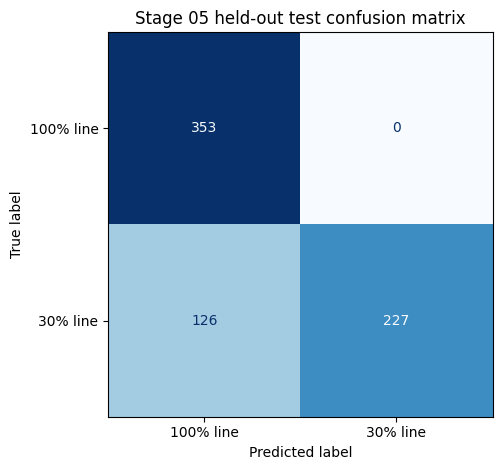

TN, FP, FN, TP: 353 0 126 227


In [10]:
cm=confusion_matrix(y_test,pred,labels=[0,1])
disp=ConfusionMatrixDisplay(cm,display_labels=['100% line','30% line'])
disp.plot(values_format='d',cmap='Blues',colorbar=False)
plt.title('Stage 05 held-out test confusion matrix')
plt.tight_layout();plt.show()
print('TN, FP, FN, TP:',int(cm[0,0]),int(cm[0,1]),int(cm[1,0]),int(cm[1,1]))

## Cell 11 — ROC and Precision–Recall curves

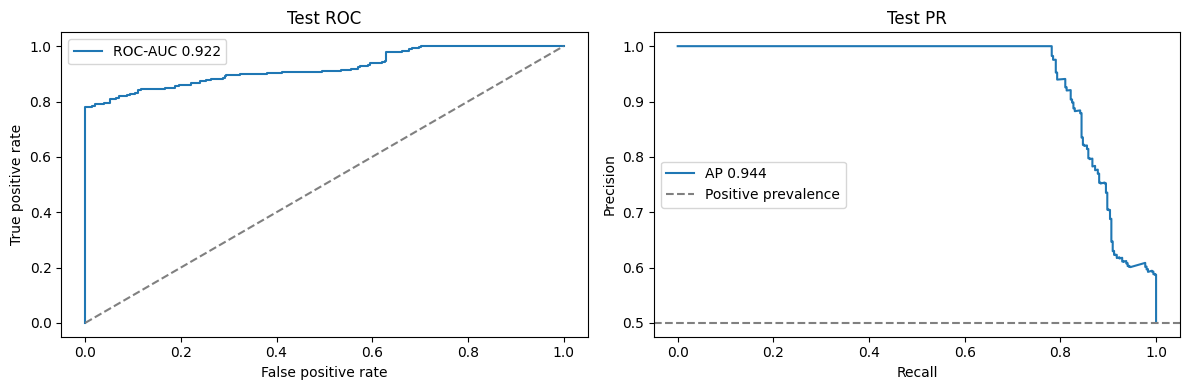

In [11]:
fpr,tpr,_=roc_curve(y_test,scores)
pr,re,_=precision_recall_curve(y_test,scores)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(fpr,tpr,label=f"ROC-AUC {metrics['roc_auc']:.3f}")
ax[0].plot([0,1],[0,1],ls='--',color='gray');ax[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC');ax[0].legend()
ax[1].plot(re,pr,label=f"AP {metrics['average_precision']:.3f}")
ax[1].axhline(y_test.mean(),ls='--',color='gray',label='Positive prevalence')
ax[1].set(xlabel='Recall',ylabel='Precision',title='Test PR');ax[1].legend()
plt.tight_layout();plt.show()

## Cell 12 — Compare frozen validation and final test (descriptive, no re-selection)

In [12]:
compare=pd.DataFrame({'validation_selected_stage04':stage04_manifest['selected_validation_metrics'],
                      'test_stage05':metrics})
print(compare.round(4).to_string())
print('Differences may reflect temporal distribution changes, not independent farm generalization.')

                   validation_selected_stage04  test_stage05
accuracy                                0.8818        0.8215
balanced_accuracy                       0.8818        0.8215
precision                               0.9599        1.0000
recall                                  0.7970        0.6431
f1                                      0.8709        0.7828
roc_auc                                 0.9791        0.9215
pr_auc                                  0.9793           NaN
average_precision                          NaN        0.9443
mcc                                        NaN        0.6884
log_loss                                   NaN        0.5233
brier_score                                NaN        0.1297
Differences may reflect temporal distribution changes, not independent farm generalization.


## Cell 13 — Error audit by date (descriptive only)

In [13]:
test_predictions=test[['timestamp','line','target']].copy()
test_predictions['prediction']=pred
test_predictions['score_reduced_irrigation']=scores
test_predictions['correct']=test_predictions['prediction'].eq(test_predictions['target'])
test_predictions['date_utc']=test_predictions['timestamp'].dt.strftime('%Y-%m-%d')
daily=test_predictions.groupby('date_utc').agg(samples=('correct','size'),correct=('correct','sum'),accuracy=('correct','mean'))
print('Test-day summary:')
display(daily.head(20))
print('Wrongly classified rows:',int((~test_predictions.correct).sum()))
# This audit is for documentation. Do NOT modify model, threshold, or feature engineering after seeing it.

Test-day summary:


,samples,correct,accuracy
date_utc,,,
2023-08-30,36,18,0.500000
2023-08-31,48,24,0.500000
2023-09-01,48,30,0.625000
2023-09-02,48,24,0.500000
2023-09-03,48,28,0.583333
2023-09-04,48,28,0.583333
2023-09-05,48,46,0.958333
2023-09-06,48,48,1.000000
2023-09-07,48,48,1.000000


Wrongly classified rows: 126


## Cell 14 — Time-series-oriented accuracy plot

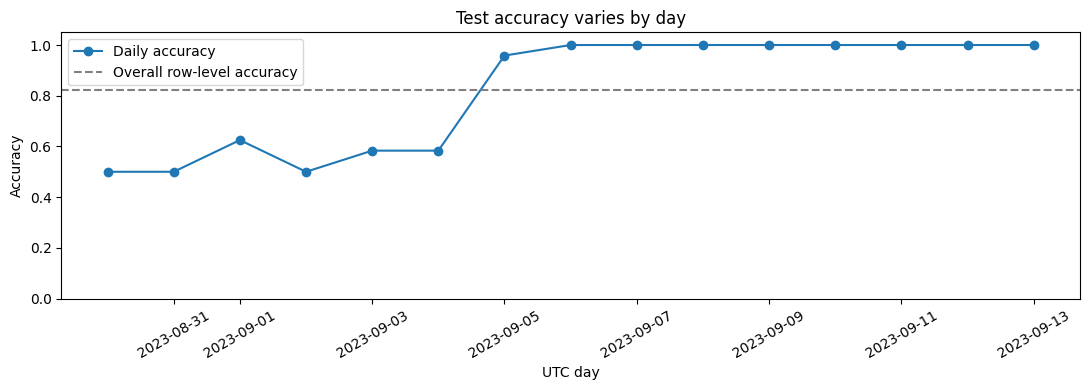

Daily points are not independent experimental farms or line replicates.


In [14]:
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(pd.to_datetime(daily.index),daily['accuracy'],marker='o',label='Daily accuracy')
ax.axhline(metrics['accuracy'],ls='--',color='gray',label='Overall row-level accuracy')
ax.set(ylim=(0,1.05),xlabel='UTC day',ylabel='Accuracy',title='Test accuracy varies by day')
ax.legend();plt.xticks(rotation=30);plt.tight_layout();plt.show()
print('Daily points are not independent experimental farms or line replicates.')

## Cell 15 — Inference schema and reproducibility metadata

In [15]:
source_hashes={str(Z3):hashlib.sha256(Z3.read_bytes()).hexdigest(),str(Z4):hashlib.sha256(Z4.read_bytes()).hexdigest()}
manifest05={
  'project':'RC3SI','stage':'05 Frozen Held-Out Test Evaluation',
  'evaluated_at_utc':datetime.now(timezone.utc).isoformat(),
  'dataset_description':'Parma 2023 one-farm one-season known physical lines',
  'target_definition':'0=100%-irrigation Line 1; 1=30%-irrigation Line 3',
  'NOT_a_stress_diagnosis':True,'NOT_early_warning_verified':True,
  'model_source':'Stage 04 frozen validation-selected TRAIN-only model',
  'model_family':stage04_manifest['selected_model_family'],
  'features_ordered':features,'threshold':THRESHOLD,
  'model_selection':'Stage 04 validation F1, no test tuning',
  'train_size':2165,'validation_size':660,'test_size':int(len(test)),
  'test_metrics':{k:float(v) for k,v in metrics.items()},
  'confusion_matrix_rows_true_cols_pred':cm.tolist(),
  'source_zip_sha256':source_hashes,
  'sklearn_version':sklearn.__version__,
  'limitations':['single season and field','one line per treatment means line/treatment confounding',
   'temporal dependence: hourly rows are not independent replication',
   'no physiological stress or event-onset labels',
   'no guarantee of generalization to unseen lines, years or farms']
}
print(json.dumps({k:v for k,v in manifest05.items() if k not in ('source_zip_sha256','test_metrics')},indent=2))

{
  "project": "RC3SI",
  "stage": "05 Frozen Held-Out Test Evaluation",
  "evaluated_at_utc": "2026-10-20T17:09:56.231228+00:00",
  "dataset_description": "Parma 2023 one-farm one-season known physical lines",
  "target_definition": "0=100%-irrigation Line 1; 1=30%-irrigation Line 3",
  "NOT_a_stress_diagnosis": true,
  "NOT_early_warning_verified": true,
  "model_source": "Stage 04 frozen validation-selected TRAIN-only model",
  "model_family": "HistGradientBoosting",
  "features_ordered": [
    "soil_humidity_lag_1h",
    "soil_humidity_lag_6h",
    "soil_humidity",
    "soil_humidity_lag_3h",
    "soil_humidity_prev_3h_mean",
    "soil_humidity_prev_6h_mean",
    "soil_electrical_conductivity",
    "soil_humidity_change_3h",
    "soil_humidity_change_1h",
    "soil_temperature"
  ],
  "threshold": 0.5,
  "model_selection": "Stage 04 validation F1, no test tuning",
  "train_size": 2165,
  "validation_size": 660,
  "test_size": 706,
  "confusion_matrix_rows_true_cols_pred": [
    [
 

## Cell 16 — Export final frozen model and test evidence ZIP

In [16]:
OUT=Path('rc3si_stage05_outputs'); OUT.mkdir(exist_ok=True)
(OUT/'final_model_stage04_frozen.joblib').write_bytes(model_bytes)
(OUT/'stage05_manifest.json').write_text(json.dumps(manifest05,indent=2),encoding='utf-8')
pd.DataFrame([metrics]).to_csv(OUT/'test_metrics.csv',index=False)
pd.DataFrame(cm,index=['actual_100','actual_30'],columns=['predicted_100','predicted_30']).to_csv(OUT/'test_confusion_matrix.csv')
test_predictions.to_csv(OUT/'heldout_test_predictions.csv',index=False)
compare.to_csv(OUT/'validation_vs_test_metrics.csv')
daily.to_csv(OUT/'test_daily_accuracy.csv')
(OUT/'inference_features.json').write_text(json.dumps({'features_ordered':features,'threshold':THRESHOLD,'positive_class':'30%-irrigation line; NOT measured stress'},indent=2),encoding='utf-8')
(OUT/'README_LIMITATIONS.txt').write_text('For demonstration: one farm, one season (2023), one physical line per treatment; this is historical irrigation-pattern classification, not measured stress detection or early warning. Model is frozen from Stage 04. To use live API, compute exactly the same historical features in chronological order and validate schema and units. Only load trusted joblib artifacts.\n',encoding='utf-8')
RESULT=Path('RC3SI_Stage05_Outputs_v1.zip')
with zipfile.ZipFile(RESULT,'w',zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()):z.write(f,arcname=f.name)
print('Created',RESULT,'bytes:',RESULT.stat().st_size)
print('Includes:')
with zipfile.ZipFile(RESULT) as z:print('\n'.join(z.namelist()))

Created RC3SI_Stage05_Outputs_v1.zip bytes: 208625
Includes:
README_LIMITATIONS.txt
final_model_stage04_frozen.joblib
heldout_test_predictions.csv
inference_features.json
stage05_manifest.json
test_confusion_matrix.csv
test_daily_accuracy.csv
test_metrics.csv
validation_vs_test_metrics.csv


## Cell 17 — Download the export from Colab

In [17]:
try:
    from google.colab import files
    files.download('RC3SI_Stage05_Outputs_v1.zip')
except ImportError:
    print('Download manually from working directory: RC3SI_Stage05_Outputs_v1.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation and next steps

- The test set was evaluated only after Stage 04 froze model/feature/threshold selection. **Do not compare several alternatives on these test outcomes and then announce the best**.
- Accuracy, F1, ROC-AUC, and AP here evaluate the binary *recorded treatment-line identity pattern*. Because each treatment occurs on only one physical line, the evaluation cannot separate sensor/line differences from treatment effects.
- A model score is **not** a percentage probability of physiological stress. Probability calibration was not independently demonstrated.
- Consecutive sensor rows are correlated: don't treat 706 test rows as 706 independent experimental replicates or use row-wise random confidence intervals to assert farm-level generalization.
- In the subsequent backend stage we will build a **historical-data replay demonstration**, label it accordingly, and reproduce the same feature computation in the service. We must check input schema, lag-window availability, and the saved model output against Colab.

**Please upload your executed Stage 05 `.ipynb` and `RC3SI_Stage05_Outputs_v1.zip` before proceeding to the FastAPI backend.**